## Data Frames

Create employee and department DataFrames to practice merging and aggregation

### Import Library



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

### Create DataFrames

Create employee and department tables to use in joins, summaries, and visualizations.

In [ ]:
employees = pd.DataFrame({
    'EmployeeID': [1, 2, 3, 4, 5],
    'Name': ['Alice', 'Bob', 'Charlie', 'David', 'Eva'],
    'DepartmentID': [101, 102, 101, 103, 105],
    'Salary': [70000, 80000, 65000, 75000, 90000],
    'Gender': ['F', 'M', 'M', 'M', 'F']  })

departments = pd.DataFrame({
    'DepartmentID': [101, 102, 103,104],
    'DepartmentName': ['HR', 'Engineering', 'Finance', 'Marketing']
})


## Joining Data

Combine employee and department records using different join types to inspect matching and unmatched records.

### Inner Join

Keep records with matching department IDs in both DataFrames.

In [ ]:
inner_join = pd.merge(employees, departments, on='DepartmentID', how='inner')
print(inner_join)

   EmployeeID     Name  DepartmentID  Salary Gender DepartmentName
0           1    Alice           101   70000      F             HR
1           2      Bob           102   80000      M    Engineering
2           3  Charlie           101   65000      M             HR
3           4    David           103   75000      M        Finance


### Left Join

Keep all employee records, including those without a matching department.

In [ ]:
left_join = pd.merge(employees, departments, on='DepartmentID', how='left')
print(left_join)

   EmployeeID     Name  DepartmentID  Salary Gender DepartmentName
0           1    Alice           101   70000      F             HR
1           2      Bob           102   80000      M    Engineering
2           3  Charlie           101   65000      M             HR
3           4    David           103   75000      M        Finance
4           5      Eva           105   90000      F            NaN


### Right Join

Keep all department records, including departments without matching employees.

In [ ]:
right_join = pd.merge(employees, departments, on='DepartmentID', how='right')
print(right_join)

   EmployeeID     Name  DepartmentID   Salary Gender DepartmentName
0         1.0    Alice           101  70000.0      F             HR
1         3.0  Charlie           101  65000.0      M             HR
2         2.0      Bob           102  80000.0      M    Engineering
3         4.0    David           103  75000.0      M        Finance
4         NaN      NaN           104      NaN    NaN      Marketing


### Outer Join

Keep records from both DataFrames to identify unmatched entries.

In [ ]:
outer_join = pd.merge(employees, departments, on='DepartmentID', how='outer')
print(outer_join)

   EmployeeID     Name  DepartmentID   Salary Gender DepartmentName
0         1.0    Alice           101  70000.0      F             HR
1         3.0  Charlie           101  65000.0      M             HR
2         2.0      Bob           102  80000.0      M    Engineering
3         4.0    David           103  75000.0      M        Finance
4         NaN      NaN           104      NaN    NaN      Marketing
5         5.0      Eva           105  90000.0      F            NaN


## Handling Missing Values

Check missing values introduced by the joins, fill selected fields, and remove records missing employee IDs.

In [ ]:
print(outer_join.isnull().sum())

outer_join_filled = outer_join.fillna({'DepartmentName': 'Unknown', 'Name': 'No Employee', 'Salary': 0})
print(outer_join_filled)

cleaned_data = outer_join.dropna(subset=['EmployeeID'])
print(cleaned_data)

EmployeeID        1
Name              1
DepartmentID      0
Salary            1
Gender            1
DepartmentName    1
dtype: int64
   EmployeeID         Name  DepartmentID   Salary Gender DepartmentName
0         1.0        Alice           101  70000.0      F             HR
1         3.0      Charlie           101  65000.0      M             HR
2         2.0          Bob           102  80000.0      M    Engineering
3         4.0        David           103  75000.0      M        Finance
4         NaN  No Employee           104      0.0    NaN      Marketing
5         5.0          Eva           105  90000.0      F        Unknown
   EmployeeID     Name  DepartmentID   Salary Gender DepartmentName
0         1.0    Alice           101  70000.0      F             HR
1         3.0  Charlie           101  65000.0      M             HR
2         2.0      Bob           102  80000.0      M    Engineering
3         4.0    David           103  75000.0      M        Finance
5         5.0      Eva 

## Grouping and Aggregation

Summarize employee counts and salary values across departments and genders.

### Average Salary by Department

Calculate the mean salary for each department ID.

In [ ]:
avg_salary = employees.groupby('DepartmentID')['Salary'].mean().reset_index()

print("Average Salary by Department:")
print(avg_salary)


Average Salary by Department:
   DepartmentID   Salary
0           101  67500.0
1           102  80000.0
2           103  75000.0
3           105  90000.0


### Employee Count by Department

Count employee records within each department.

In [ ]:
employee_count = employees.groupby('DepartmentID').size().reset_index(name='EmployeeCount')

print("Employee Count by Department:")
print(employee_count)

Employee Count by Department:
   DepartmentID  EmployeeCount
0           101              2
1           102              1
2           103              1
3           105              1


### Employee Count by Department and Gender

Count employee records by department and gender.

In [ ]:
multi_group = employees.groupby(['DepartmentID', 'Gender']).size().reset_index(name='EmployeeCount')

print("Employee Count by Department and Gender:")
print(multi_group)

Employee Count by Department and Gender:
   DepartmentID Gender  EmployeeCount
0           101      F              1
1           101      M              1
2           102      M              1
3           103      M              1
4           105      F              1


### Salary Summary

Calculate the mean, minimum, and maximum salary for matched departments.

In [ ]:
agg = inner_join.groupby("DepartmentName")["Salary"].agg(["mean", "min", "max"])
print(agg)

                   mean    min    max
DepartmentName                       
Engineering     80000.0  80000  80000
Finance         75000.0  75000  75000
HR              67500.0  65000  70000


### Salary Range

Calculate the difference between the highest and lowest salaries in each department.

In [ ]:
def salary_range(x):
  return x.max() - x.min()

salary_range_data = employees.groupby("DepartmentID")["Salary"].agg(salary_range).reset_index()
salary_range_data.rename(columns={"Salary": "SalaryRange"}, inplace=True)

print(salary_range_data)

   DepartmentID  SalaryRange
0           101         5000
1           102            0
2           103            0
3           105            0


### Combining Joins and Aggregations

Add average salaries to the department table while retaining departments with no employee records.

In [ ]:
final = pd.merge(departments, avg_salary, on="DepartmentID", how="left")
final.rename(columns={'Salary': 'AverageSalary'}, inplace= True)

print(final)

   DepartmentID DepartmentName  AverageSalary
0           101             HR        67500.0
1           102    Engineering        80000.0
2           103        Finance        75000.0
3           104      Marketing            NaN


## Visualization

Compare average salaries across departments with matching employee records using a bar chart.

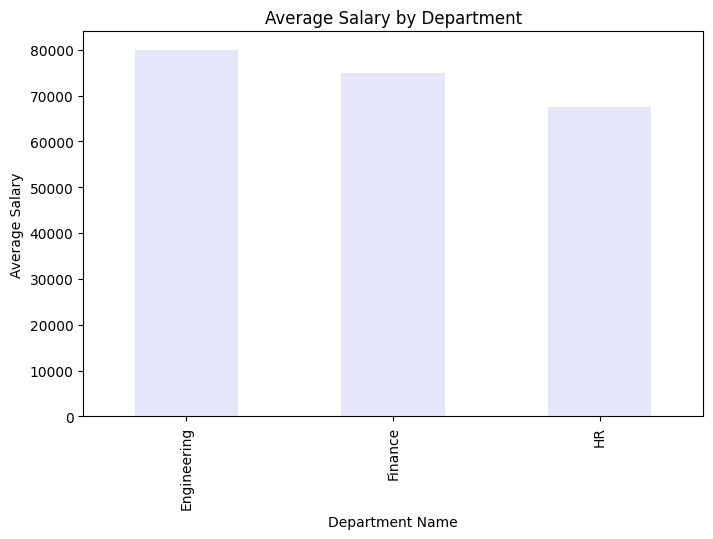

In [ ]:
report = inner_join.groupby('DepartmentName')['Salary'].mean()

plt.figure(figsize=(8, 5))
report.plot(kind='bar', color='lavender')

plt.title('Average Salary by Department')
plt.xlabel('Department Name')
plt.ylabel('Average Salary')

plt.show()